## Import

In [1]:
import sys
sys.path.append("..")

import os
import pandas as pd
import json
import numpy as np
import scipy
from scipy.stats import kendalltau
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns

from pereval.feature_extractor import FeatureExtractor
from pereval.pseudo_rating import MahalanobisRating, MarginalMahalanobisRating, \
                                  RelativeMahalanobisRating

import warnings
warnings.filterwarnings('ignore')

In [2]:
# We will use this to load the necessary file paths from the environment

from dotenv import load_dotenv

load_dotenv()

True

## Prepare the user ratings dataframe

In the following cells, we first load the results from our PsyNet experiment which was used to host the listening test.

In [3]:
ru_results_path = os.getenv("RU_RESULTS_PATH")
en_results_path = os.getenv("EN_RESULTS_PATH")

In [4]:
df_ru = pd.read_csv(ru_results_path)
df_en = pd.read_csv(en_results_path)

In [5]:
df_ru["order"] = df_ru["order"].apply(lambda x: json.loads(x))
df_en["order"] = df_en["order"].apply(lambda x: json.loads(x))

In [6]:
naturalness = {"a": [],
               "b": [],
               "c": [],
               "d": [],
               "e": []}

expression = {"a": [],
              "b": [],
              "c": [],
              "d": [],
              "e": []}

score_name_lst = []

for i, row in df_ru.iterrows():
    score_name_lst.append(row["stimulus_name"])
    for j in range(5):
        model_id = row["order"][j]
        ratings = row.filter(like=f"Q{j+1}")
        naturalness[model_id].append(ratings.filter(like="Естесственность").values[0])
        expression[model_id].append(ratings.filter(like="Экспрессивность").values[0])

for i, row in df_en.iterrows():
    score_name_lst.append(row["stimulus_name"])
    for j in range(5):
        model_id = row["order"][j]
        ratings = row.filter(like=f"Q{j+1}")
        naturalness[model_id].append(ratings.filter(like="Naturalness").values[0])
        expression[model_id].append(ratings.filter(like="Expression").values[0])

## Load embeddings

In [7]:
# The reference set of embeddings (human performances)

ref_emb_path = os.getenv("REF_EMB_PATH")

ref_emb, ref_score_lst, ref_perf_lst = FeatureExtractor().extract_features(ref_emb_path)

In [8]:
# The embeddings to estimate covariance matrices (can be the same as the reference set)

cov_emb_path = os.getenv("COV_EMB_PATH")

cov_emb, cov_score_lst, cov_perf_lst = FeatureExtractor().extract_features(cov_emb_path)

In [9]:
# The embeddings for model-generated performances

test_emb_path = {}

test_emb_path["a"] = os.getenv("TEST_EMB_PATH_A")
test_emb_path["b"] = os.getenv("TEST_EMB_PATH_B")
test_emb_path["c"] = os.getenv("TEST_EMB_PATH_C")
test_emb_path["d"] = os.getenv("TEST_EMB_PATH_D")
test_emb_path["e"] = os.getenv("TEST_EMB_PATH_E")

In [10]:
test_emb = {}
score_lst = {}
perf_lst = {}

for model_id in ["a", "b", "c", "d", "e"]:
    test_emb[model_id], score_lst[model_id], perf_lst[model_id] = FeatureExtractor().extract_features(test_emb_path[model_id])

## Covariance estimation

Please choose a Mahalanobis pseudo rater of your choice.

In [11]:
pseudo_rater = RelativeMahalanobisRating()
pseudo_rater.fit_precision(cov_emb=cov_emb,
                           score_lst=cov_score_lst)

#pseudo_rater = MahalanobisRating()
#pseudo_rater.fit_precision(cov_emb=cov_emb,
#                           score_lst=cov_score_lst)

#pseudo_rater = MarginalMahalanobisRating()
#pseudo_rater.fit_precision(cov_emb=cov_emb)

100%|██████████| 49/49 [00:07<00:00,  6.72it/s]


## Calculate pseudo-ratings

In [12]:
model_ratings = {"a": [],
                 "b": [],
                 "c": [],
                 "d": [],
                 "e": []}

for score_name in score_name_lst:
    human_emb = ref_emb[np.array(ref_score_lst) == score_name]
    
    for model_id in ["a", "b", "c", "d", "e"]:
        score_mask = np.array(score_lst[model_id]) == score_name
        perf_mask = np.array(perf_lst[model_id]) == "perf_0.mid"
        model_emb = test_emb[model_id][score_mask & perf_mask]

        rating = pseudo_rater.predict(emb=model_emb,
                                      ref_emb=human_emb)
        
        model_ratings[model_id].append(rating.item())

In [13]:
num_ratings = len(score_name_lst)

In [14]:
all_model_ratings = model_ratings["a"] + model_ratings["b"] + model_ratings["c"] + model_ratings["d"] + model_ratings["e"]
all_naturalness = naturalness["a"] + naturalness["b"] + naturalness["c"] + naturalness["d"] + naturalness["e"]
all_expression = expression["a"] + expression["b"] + expression["c"] + expression["d"] + expression["e"]
all_model_labels = ["M2M"] * num_ratings + ["PianoFlow-2"] * num_ratings + ["PianoFlow-16"] * num_ratings + ["PianoFlow-128"] * num_ratings + ["VirtuosoNet"] * num_ratings
all_score_names = score_name_lst * 5
all_rounds = list(range(num_ratings)) * 5

rating_df = pd.DataFrame({"model_ratings": all_model_ratings,
                          "naturalness": all_naturalness,
                          "expression": all_expression,
                          "Model": all_model_labels,
                          "score_name": all_score_names,
                          "round": all_rounds})

rating_df = rating_df.dropna()

rating_df

,model_ratings,naturalness,expression,Model,score_name,round
0,-0.154701,1.0,2.0,M2M,score_16266,0
1,-2.582124,2.0,5.0,M2M,score_4712,1
2,-1.103623,1.0,2.0,M2M,score_14719,2
3,-0.840303,1.0,1.0,M2M,score_14513,3
4,-2.622239,1.0,1.0,M2M,score_14423,4
...,...,...,...,...,...,...
875,-1.201637,1.0,3.0,VirtuosoNet,score_19236,171
876,0.059183,3.0,4.0,VirtuosoNet,score_14806,172
877,0.177990,5.0,4.0,VirtuosoNet,score_13917,173
878,-0.352715,2.0,5.0,VirtuosoNet,score_15207,174


In [15]:
rating_df_sem = rating_df.groupby(["score_name", "Model"])[["naturalness", "expression", "model_ratings"]].sem()
rating_df_sem = rating_df_sem.rename(columns={"naturalness": "naturalness_sem",
                                              "expression": "expression_sem"})
rating_df_sem = rating_df_sem.drop(columns=["model_ratings"]).reset_index()

rating_df_mean = rating_df.groupby(["score_name", "Model"])[["naturalness", "expression", "model_ratings"]].mean().reset_index()

In [16]:
rating_df = pd.merge(rating_df_mean, rating_df_sem, how="outer")
rating_df

,score_name,Model,naturalness,expression,model_ratings,naturalness_sem,expression_sem
0,score_13791,M2M,1.20,1.20,-0.891480,0.200000,0.200000
1,score_13791,PianoFlow-128,3.40,3.00,-0.011188,0.678233,0.547723
2,score_13791,PianoFlow-16,3.60,3.20,-0.005597,0.871780,0.800000
3,score_13791,PianoFlow-2,3.00,2.60,0.122207,0.894427,0.600000
4,score_13791,VirtuosoNet,2.20,2.00,0.039500,0.489898,0.316228
...,...,...,...,...,...,...,...
140,score_6592,M2M,2.25,3.25,-2.801809,0.478714,1.030776
141,score_6592,PianoFlow-128,2.75,3.25,-0.078622,0.629153,0.853913
142,score_6592,PianoFlow-16,3.00,3.25,0.118919,0.816497,0.629153
143,score_6592,PianoFlow-2,2.75,3.00,-0.183206,0.629153,0.707107


## Calculate agreement with MOS

Finally, we will calculate the agreement of pseudo-ratings with human MOS using the Kendall-tau rank correlation.

In [17]:
r_lst = []

for score_name in set(score_name_lst):
    rating_subset = rating_df[rating_df["score_name"] == score_name]

    r = kendalltau(rating_subset["model_ratings"], rating_subset["naturalness"]).statistic

    # Uncomment this cell to calculate the agreement with the MOS of expression 
    #r = kendalltau(rating_subset["model_ratings"], rating_subset["expression"]).statistic
    
    r_lst.append(r)

#########################
# Calculate the confidence intervals

t_critical = scipy.stats.t.ppf(q = 0.975, df=len(r_lst) - 1)

sample_stdev = np.std(r_lst, ddof=1)
sigma = sample_stdev / np.sqrt(len(r_lst))  # Standard deviation estimate
margin_of_error = t_critical * sigma

print("95% CI:", np.mean(r_lst), '+-', margin_of_error)

95% CI: 0.5089704941418292 +- 0.13439418696061187


In [18]:
rating_df = rating_df.drop(columns="score_name")

In [19]:
sns.set_style('darkgrid', {'legend.frameon':True})

colors = dict(zip(rating_df["Model"].unique(), sns.color_palette('Set1')))

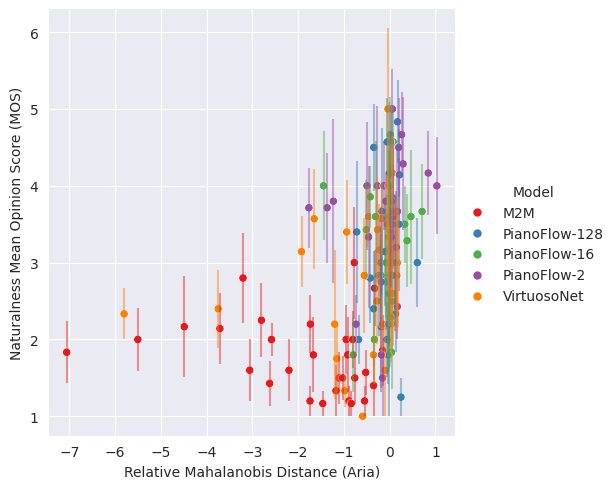

In [20]:
g = sns.relplot(data=rating_df, x="model_ratings", y="naturalness", 
                hue="Model", palette=colors, legend='full')

models = rating_df['Model'].unique()
for ax in g.axes.flat:
    for model in models:
        color = colors[model]
        subset = rating_df[rating_df['Model'] == model]
        ax.errorbar(x=subset['model_ratings'], y=subset['naturalness'],
                    yerr=subset['naturalness_sem'], fmt='none', ecolor=color,
                    alpha=0.45)

plt.xlabel("Relative Mahalanobis Distance (Aria)")
plt.ylabel("Naturalness Mean Opinion Score (MOS)")
plt.show()